# Task 4: Location-based Analysis
**Cognifyz Technologies - Machine Learning Internship**
**Intern:** Manish Chandra Raturi
**Dataset:** Restaurant dataset (`Dataset.csv`, 9,551 restaurants, 21 columns)

**Objective:** Perform a geographical analysis of the restaurants.

**Steps:** (1) Map the latitude/longitude distribution, (2) Group by city and locality and study concentration, (3) Compute average rating / cuisine / price statistics per area, (4) Report patterns.

## 1. Setup and load data

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30, "display.width", 170)
df = pd.read_csv("Dataset.csv", encoding="utf-8-sig")
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
df["Currency"] = df["Currency"].str.replace(r"[^\x00-\x7F]", "", regex=True)
print("Shape:", df.shape)
print("Countries (codes):", df["Country Code"].nunique(), "| Cities:", df["City"].nunique(), "| Localities:", df["Locality Verbose"].nunique())

Shape: (9551, 21)
Countries (codes): 15 | Cities: 141 | Localities: 1265


## 2. Clean the coordinates
Two problems are checked before drawing any map:
1. `(0, 0)` coordinates - a placeholder meaning "unknown" (middle of the ocean).
2. Points more than 2 degrees (~220 km) from the median of their own city - almost certainly wrong GPS data (for example one coordinate stored as 0). A threshold of 2 degrees is used on purpose: a first check at 1 degree wrongly flagged 13 correct points in "Rest of Hawaii", a city label that legitimately spans several islands.

Cleaning is applied **only to the map**. Group statistics use all rows, because a restaurant with a bad GPS point still belongs to its city.

In [2]:
geo = df.copy()
zero = (geo.Latitude == 0) & (geo.Longitude == 0)
med = geo[~zero].groupby("City")[["Latitude", "Longitude"]].transform("median")
geo["dev_deg"] = np.sqrt((geo.Latitude - med.Latitude) ** 2 + (geo.Longitude - med.Longitude) ** 2)
far = geo["dev_deg"] > 2.0                     # more than ~220 km from the city's median point
geo["coord_ok"] = ~zero & ~far

print("(0,0) coordinates      :", zero.sum())
print("Far from own city (>2 deg):", far.sum())
print("Usable for the map      :", geo.coord_ok.sum(), f"of {len(geo)}")
print("\nSample of far-from-city points:")
display(geo.loc[far, ["Restaurant Name", "City", "Latitude", "Longitude", "dev_deg"]].sort_values("dev_deg", ascending=False))
print("\nLargest deviations that are NOT flagged (all legitimate - Hawaii islands are ~1.5 degrees apart):")
display(geo.loc[~far & ~zero].nlargest(4, "dev_deg")[["Restaurant Name", "City", "dev_deg"]])
print("\nWhere are the (0,0) rows by city?")
print(geo.loc[zero, "City"].value_counts().head(6))
mp = geo[geo.coord_ok].copy()

(0,0) coordinates      : 497
Far from own city (>2 deg): 3
Usable for the map      : 9051 of 9551

Sample of far-from-city points:


,Restaurant Name,City,Latitude,Longitude,dev_deg
8620,InnerChef,Noida,28.0,0.000000,77.355857
3513,Test Restaruants for Medio,New Delhi,35.0,34.000000,43.673658
9312,Winona Forever,Auckland,0.0,174.779441,36.850867



Largest deviations that are NOT flagged (all legitimate - Hawaii islands are ~1.5 degrees apart):


,Restaurant Name,City,dev_deg
417,Kona Brewing Company,Rest of Hawaii,1.488827
416,Giovanni's Shrimp Truck,Rest of Hawaii,1.448491
435,Wailana Coffee House,Rest of Hawaii,1.191650
433,Eggs 'n Things,Rest of Hawaii,1.186043



Where are the (0,0) rows by city?
City
New Delhi    233
Noida         93
Gurgaon       48
Faridabad     22
Vadodara      10
Mangalore      9
Name: count, dtype: int64


## 3. Visualise the distribution on maps

In [3]:
# Countries: label each code with its currency (taken from the data itself)
cc = df.groupby("Country Code").agg(n=("Restaurant ID", "count"), currency=("Currency", lambda s: s.mode().iat[0]), cities=("City", "nunique"))
display(cc.sort_values("n", ascending=False))
print("Note: the currency labels come straight from the file. Code 162 shows 'Botswana Pula' although its cities (e.g. Makati City, Mandaluyong City) are in the Philippines, so that label is an error in the source data. It does not affect this analysis because costs are never compared across currencies.")

,n,currency,cities
Country Code,,,
1,8652,Indian Rupees(Rs.),43
216,434,Dollar($),35
215,80,Pounds(),4
214,60,Emirati Diram(AED),3
189,60,Rand(R),6
30,60,Brazilian Real(R$),3
148,40,NewZealand($),2
208,34,Turkish Lira(TL),2
14,24,Dollar($),23


Note: the currency labels come straight from the file. Code 162 shows 'Botswana Pula' although its cities (e.g. Makati City, Mandaluyong City) are in the Philippines, so that label is an error in the source data. It does not affect this analysis because costs are never compared across currencies.


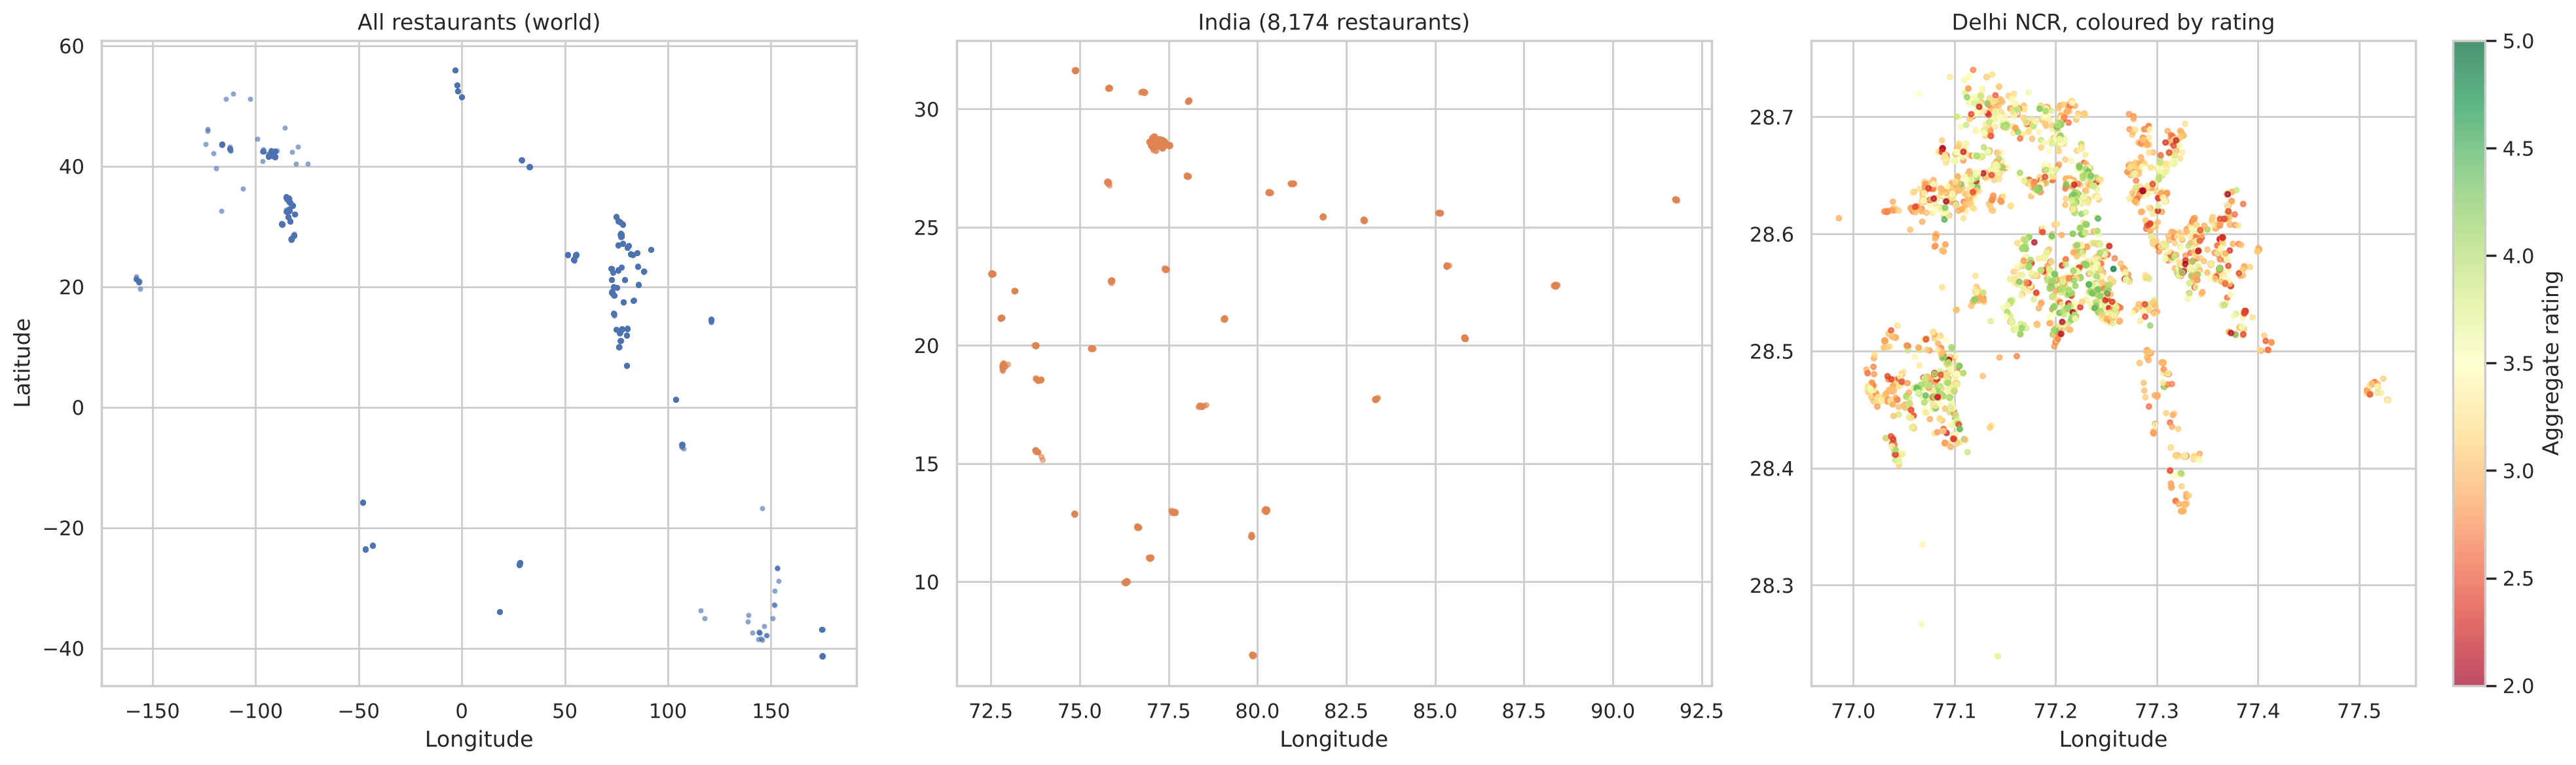

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

ax[0].scatter(mp.Longitude, mp.Latitude, s=4, alpha=0.5, color="#4C72B0")
ax[0].set_title("All restaurants (world)"); ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude")

india = mp[(mp.Longitude.between(68, 98)) & (mp.Latitude.between(6, 37))]
ax[1].scatter(india.Longitude, india.Latitude, s=6, alpha=0.5, color="#DD8452")
ax[1].set_title(f"India ({len(india):,} restaurants)"); ax[1].set_xlabel("Longitude")

ncr = mp[(mp.Longitude.between(76.8, 77.7)) & (mp.Latitude.between(28.2, 28.9)) & (mp["Aggregate rating"] > 0)]
sc = ax[2].scatter(ncr.Longitude, ncr.Latitude, c=ncr["Aggregate rating"], s=7, alpha=0.7, cmap="RdYlGn", vmin=2, vmax=5)
plt.colorbar(sc, ax=ax[2], label="Aggregate rating")
ax[2].set_title("Delhi NCR, coloured by rating"); ax[2].set_xlabel("Longitude")
plt.tight_layout(); plt.savefig("task4_maps.png", dpi=130); plt.show()

In [5]:
# Interactive maps (open the .html files in any browser)
centre = [mp.Latitude.median(), mp.Longitude.median()]
m1 = folium.Map(location=[28.6139, 77.2090], zoom_start=10, tiles="cartodbpositron")
HeatMap(mp[["Latitude", "Longitude"]].values.tolist(), radius=7, blur=10).add_to(m1)
m1.save("task4_heatmap.html")

top = mp[(mp["Aggregate rating"] >= 4.5)]
m2 = folium.Map(location=[28.6139, 77.2090], zoom_start=10, tiles="cartodbpositron")
cluster = MarkerCluster().add_to(m2)
for _, r in top.iterrows():
    folium.Marker([r.Latitude, r.Longitude],
                  popup=f"{r['Restaurant Name']}<br>{r['City']}<br>{r['Cuisines']}<br>Rating {r['Aggregate rating']}").add_to(cluster)
m2.save("task4_top_rated_map.html")
print("Saved task4_heatmap.html (density) and task4_top_rated_map.html (", len(top), "restaurants rated 4.5+ )")

Saved task4_heatmap.html (density) and task4_top_rated_map.html ( 297 restaurants rated 4.5+ )


## 4. Concentration by city and locality

Top 10 cities by restaurant count:


,restaurants,share,cumulative share
City,,,
New Delhi,5473,57.3%,57.3%
Gurgaon,1118,11.7%,69.0%
Noida,1080,11.3%,80.3%
Faridabad,251,2.6%,82.9%
Ghaziabad,25,0.3%,83.2%
Ahmedabad,21,0.2%,83.4%
Amritsar,21,0.2%,83.6%
Bhubaneshwar,21,0.2%,83.9%
Guwahati,21,0.2%,84.1%



Delhi NCR cities ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad', 'Ghaziabad'] together: 7,947 restaurants = 83.2% of the whole dataset
Cities with fewer than 20 restaurants: 64 of 141


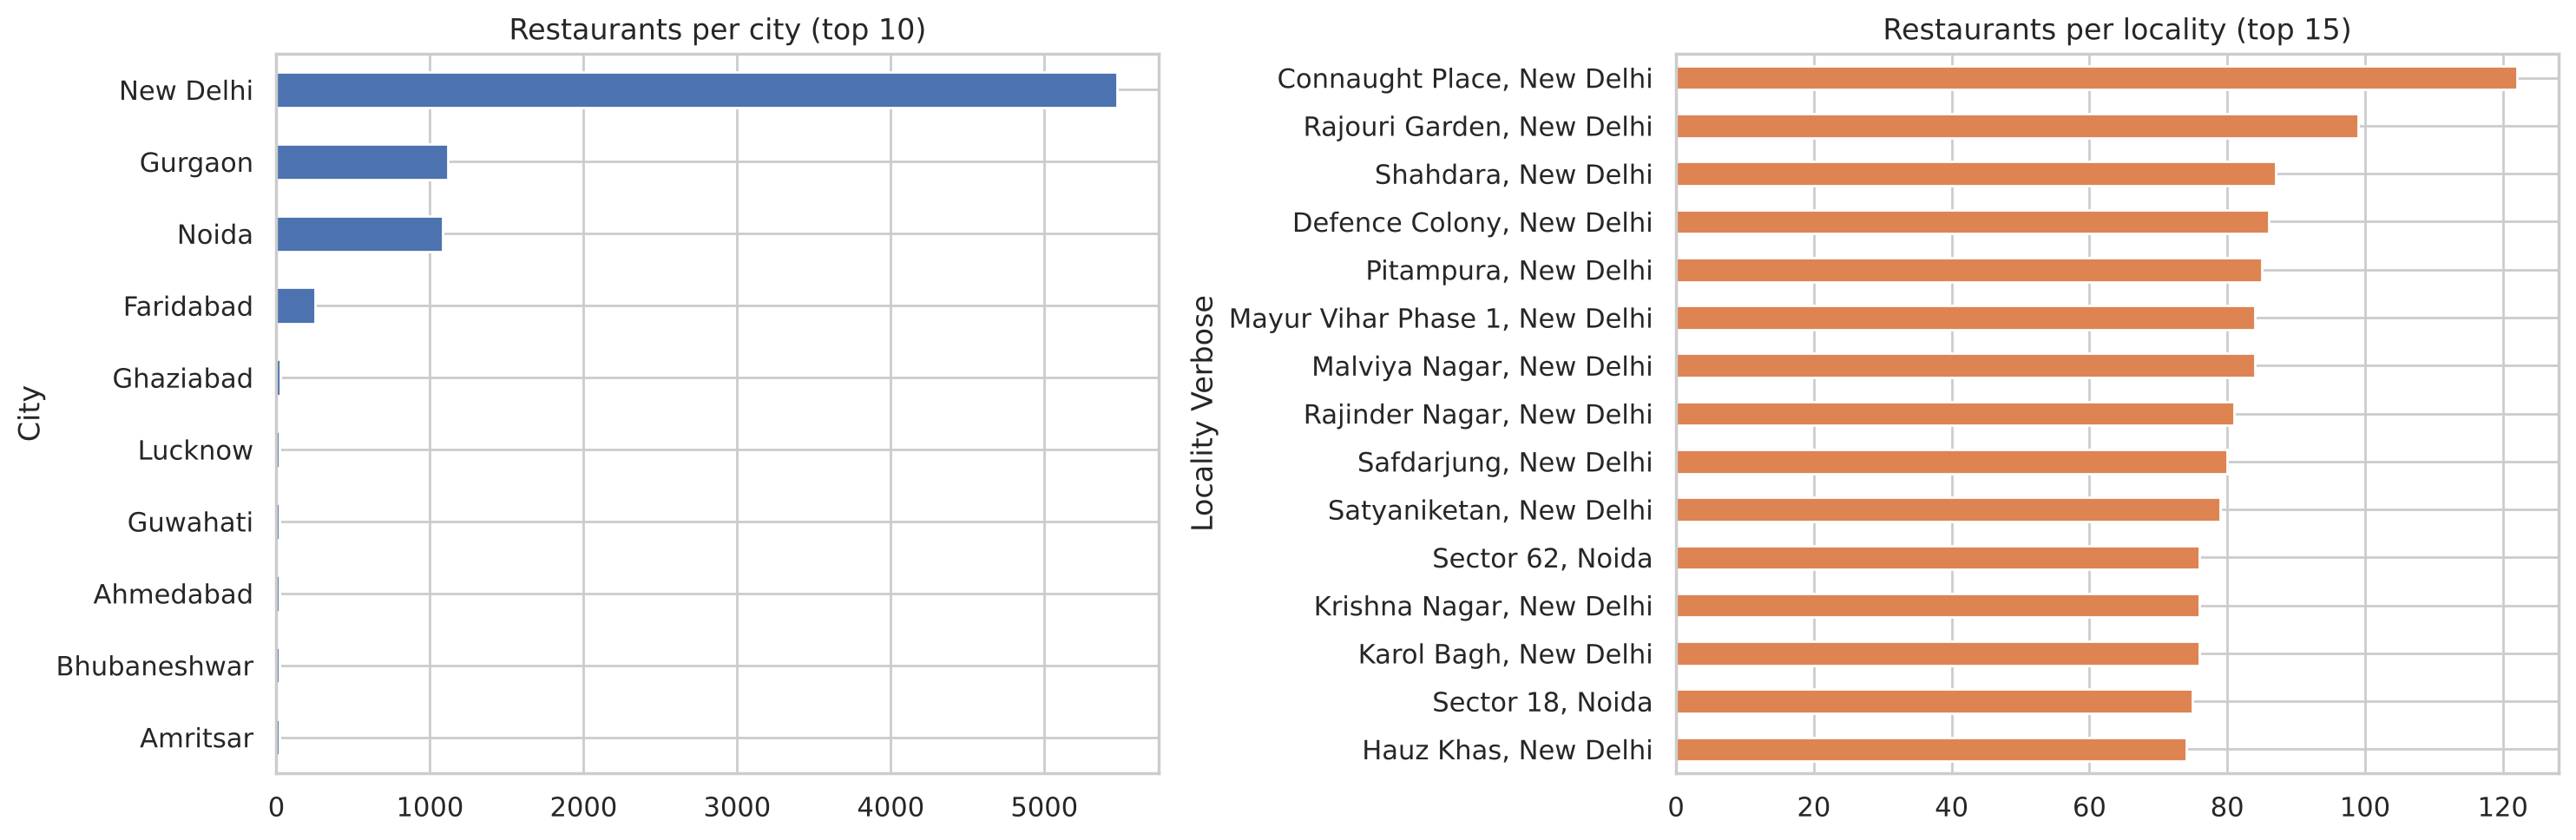

Top 10 localities hold 9.3% of all restaurants; 1265 localities in total.


In [6]:
city_counts = df["City"].value_counts()
share = (city_counts / len(df))
print("Top 10 cities by restaurant count:")
display(pd.DataFrame({"restaurants": city_counts.head(10), "share": share.head(10).map("{:.1%}".format),
                      "cumulative share": share.cumsum().head(10).map("{:.1%}".format)}))

ncr_cities = ["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"]
print(f"\nDelhi NCR cities {ncr_cities} together: {df.City.isin(ncr_cities).sum():,} restaurants = {df.City.isin(ncr_cities).mean():.1%} of the whole dataset")
print(f"Cities with fewer than 20 restaurants: {(city_counts < 20).sum()} of {len(city_counts)}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
city_counts.head(10).sort_values().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Restaurants per city (top 10)")
loc_counts = df["Locality Verbose"].value_counts()
loc_counts.head(15).sort_values().plot.barh(ax=ax[1], color="#DD8452"); ax[1].set_title("Restaurants per locality (top 15)")
plt.tight_layout(); plt.savefig("task4_concentration.png", dpi=130); plt.show()

print(f"Top 10 localities hold {loc_counts.head(10).sum() / len(df):.1%} of all restaurants; {len(loc_counts)} localities in total.")

## 5. Statistics by city and locality
Rules used so the numbers are honest:
- **Average rating** only uses rated restaurants (rating > 0). Unrated ones are not "0 stars".
- Cities/localities with too few restaurants are excluded from rankings (small samples are noisy).
- **Average cost is not compared across cities**, because it is in different currencies. `Price range` (1-4) is used instead.

In [7]:
def top_cuisine(s):
    return s.str.split(",").explode().str.strip().value_counts().index[0]

def area_stats(frame, key, min_n):
    rated = frame[frame["Aggregate rating"] > 0]
    g = frame.groupby(key).agg(restaurants=("Restaurant ID", "count"),
                               avg_price_range=("Price range", "mean"),
                               online_delivery_pct=("Has Online delivery", lambda s: (s == "Yes").mean() * 100),
                               table_booking_pct=("Has Table booking", lambda s: (s == "Yes").mean() * 100),
                               top_cuisine=("Cuisines", top_cuisine))
    g["avg_rating"] = rated.groupby(key)["Aggregate rating"].mean()
    g["unrated_pct"] = frame.groupby(key)["Aggregate rating"].apply(lambda s: (s == 0).mean() * 100)
    g["avg_votes"] = frame.groupby(key)["Votes"].mean()
    g = g[g.restaurants >= min_n].sort_values("restaurants", ascending=False)
    return g[["restaurants", "avg_rating", "avg_price_range", "avg_votes", "online_delivery_pct", "table_booking_pct", "unrated_pct", "top_cuisine"]].round(2)

city_stats = area_stats(df, "City", min_n=20)
print(f"CITY statistics (cities with >= 20 restaurants: {len(city_stats)})")
display(city_stats)
city_stats.to_csv("task4_city_statistics.csv")

CITY statistics (cities with >= 20 restaurants: 77)


,restaurants,avg_rating,avg_price_range,avg_votes,online_delivery_pct,table_booking_pct,unrated_pct,top_cuisine
City,,,,,,,,
New Delhi,5473,3.30,1.62,114.81,27.21,13.06,26.04,North Indian
Gurgaon,1118,3.33,1.86,118.21,38.01,18.25,20.39,North Indian
Noida,1080,3.16,1.60,68.04,33.70,10.37,35.56,North Indian
Faridabad,251,3.10,1.45,25.84,13.94,5.98,39.84,North Indian
Ghaziabad,25,3.10,1.80,94.64,40.00,12.00,8.00,North Indian
...,...,...,...,...,...,...,...,...
Valdosta,20,3.72,2.25,210.00,0.00,0.00,0.00,Mexican
Varanasi,20,3.51,2.45,86.45,0.00,0.00,0.00,North Indian
Vizag,20,4.00,2.35,163.85,0.00,0.00,0.00,North Indian


In [8]:
loc_stats = area_stats(df, "Locality Verbose", min_n=30)
print(f"LOCALITY statistics (localities with >= 30 restaurants: {len(loc_stats)})")
print("\nMost restaurants:")
display(loc_stats.head(10))
print("\nHighest average rating:")
display(loc_stats.sort_values("avg_rating", ascending=False).head(8))
print("\nLowest average rating:")
display(loc_stats.sort_values("avg_rating").head(8))
loc_stats.to_csv("task4_locality_statistics.csv")

LOCALITY statistics (localities with >= 30 restaurants: 98)

Most restaurants:


,restaurants,avg_rating,avg_price_range,avg_votes,online_delivery_pct,table_booking_pct,unrated_pct,top_cuisine
Locality Verbose,,,,,,,,
"Connaught Place, New Delhi",122,3.78,2.60,1050.07,42.62,44.26,2.46,North Indian
"Rajouri Garden, New Delhi",99,3.63,2.20,259.52,45.45,34.34,1.01,North Indian
"Shahdara, New Delhi",87,3.00,1.14,7.69,0.00,0.00,52.87,North Indian
"Defence Colony, New Delhi",86,3.49,1.93,181.37,56.98,27.91,8.14,North Indian
"Pitampura, New Delhi",85,3.17,1.47,47.64,48.24,3.53,9.41,North Indian
"Malviya Nagar, New Delhi",84,3.42,1.77,143.90,76.19,10.71,0.00,North Indian
"Mayur Vihar Phase 1, New Delhi",84,2.99,1.30,22.52,26.19,4.76,32.14,North Indian
"Rajinder Nagar, New Delhi",81,3.06,1.43,63.84,46.91,6.17,3.70,North Indian
"Safdarjung, New Delhi",80,3.25,1.68,110.46,35.00,8.75,13.75,North Indian



Highest average rating:


,restaurants,avg_rating,avg_price_range,avg_votes,online_delivery_pct,table_booking_pct,unrated_pct,top_cuisine
Locality Verbose,,,,,,,,
"Sector 29, Gurgaon",38,3.89,2.87,549.50,28.95,68.42,0.00,North Indian
"Cyber Hub, DLF Cyber City, Gurgaon",41,3.86,2.80,882.56,51.22,53.66,0.00,North Indian
"DLF Mall of India, Sector 18, Noida, Noida",31,3.84,2.23,267.00,38.71,32.26,0.00,Fast Food
"Khan Market, New Delhi",44,3.80,2.70,646.93,29.55,34.09,2.27,Italian
"Connaught Place, New Delhi",122,3.78,2.60,1050.07,42.62,44.26,2.46,North Indian
"Greater Kailash (GK) 1, New Delhi",66,3.70,2.21,160.17,62.12,24.24,0.00,Fast Food
"Rajouri Garden, New Delhi",99,3.63,2.20,259.52,45.45,34.34,1.01,North Indian
"Vijay Nagar, New Delhi",31,3.61,1.48,395.84,41.94,12.90,0.00,Chinese



Lowest average rating:


,restaurants,avg_rating,avg_price_range,avg_votes,online_delivery_pct,table_booking_pct,unrated_pct,top_cuisine
Locality Verbose,,,,,,,,
"Sainik Farms, New Delhi",35,2.75,1.14,3.43,14.29,0.00,71.43,North Indian
"Palam, New Delhi",60,2.90,1.20,2.08,1.67,0.00,80.00,North Indian
"Najafgarh, New Delhi",60,2.90,1.07,0.60,0.00,3.33,98.33,North Indian
"Uttam Nagar, New Delhi",59,2.91,1.08,5.02,25.42,0.00,40.68,North Indian
"Mayur Vihar Phase 3, New Delhi",32,2.94,1.28,13.22,6.25,6.25,37.50,North Indian
"Sector 132, Noida",43,2.94,1.40,6.30,11.63,2.33,67.44,North Indian
"MG Road, New Delhi",34,2.95,1.26,0.79,5.88,2.94,94.12,North Indian
"Greater Noida, Noida",38,2.95,1.53,15.87,39.47,13.16,36.84,North Indian


## 6. Patterns and insights

Average rating by price range:


,mean,count
Price range,,
1,3.239,2744
2,3.377,2711
3,3.777,1373
4,3.891,575


Spearman correlation (price range vs rating): 0.402 (p = 3e-285)

Average rating by service:
Has Online delivery
No     3.467
Yes    3.381
Name: online delivery, dtype: float64
Has Table booking
No     3.414
Yes    3.588
Name: table booking, dtype: float64

Locality size vs avg rating: Spearman -0.025 (p = 0.81, n = 97 localities)

Avg rating - Delhi NCR: 3.280 | other Indian cities: 3.944 | outside India: 4.084
Unrated share - NCR: 26.9% | everywhere else: 0.6%


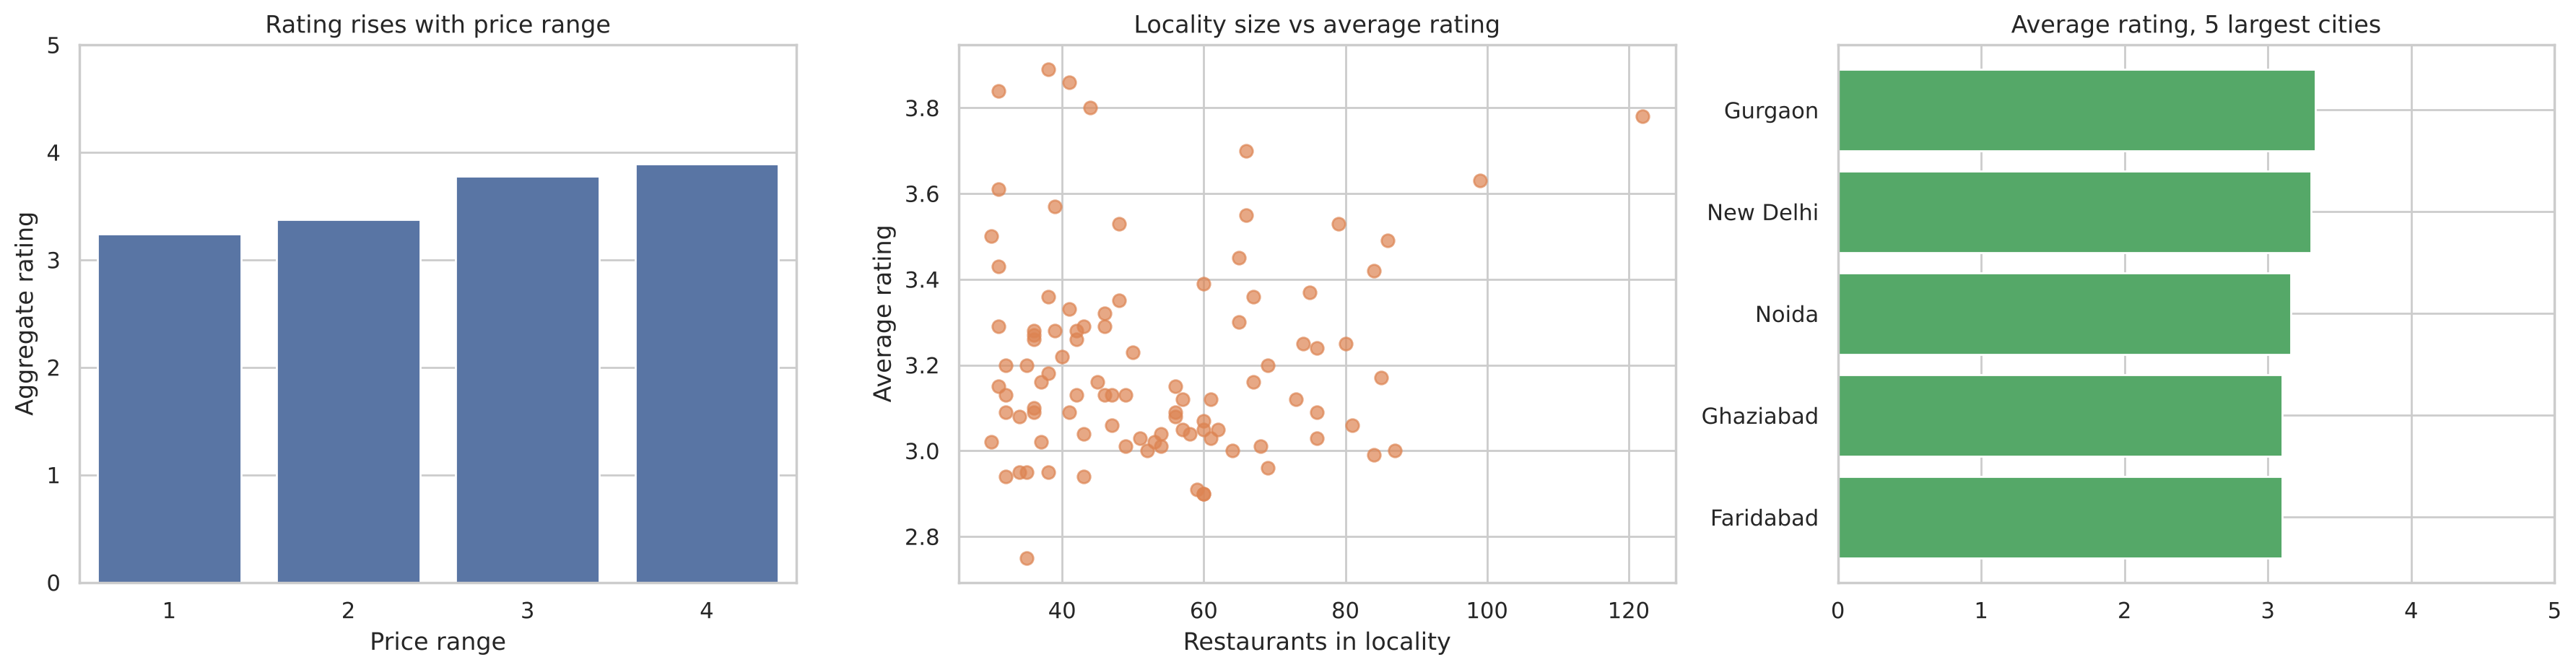

In [9]:
rated = df[df["Aggregate rating"] > 0].copy()

# 1) Rating vs price range
by_price = rated.groupby("Price range")["Aggregate rating"].agg(["mean", "count"]).round(3)
rho, p = spearmanr(rated["Price range"], rated["Aggregate rating"])
print("Average rating by price range:"); display(by_price)
print(f"Spearman correlation (price range vs rating): {rho:.3f} (p = {p:.2g})")

# 2) Online delivery / table booking vs rating
print("\nAverage rating by service:")
print(rated.groupby("Has Online delivery")["Aggregate rating"].mean().round(3).rename("online delivery"))
print(rated.groupby("Has Table booking")["Aggregate rating"].mean().round(3).rename("table booking"))

# 3) Do crowded localities rate differently? (localities with >= 30 restaurants)
ls = loc_stats.dropna(subset=["avg_rating"])
rho2, p2 = spearmanr(ls["restaurants"], ls["avg_rating"])
print(f"\nLocality size vs avg rating: Spearman {rho2:.3f} (p = {p2:.2g}, n = {len(ls)} localities)")

# 4) NCR vs rest of dataset
ncr_mask = rated.City.isin(["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"])
india_other = rated[(rated["Country Code"] == 1) & ~ncr_mask]
print(f"\nAvg rating - Delhi NCR: {rated[ncr_mask]['Aggregate rating'].mean():.3f} | other Indian cities: {india_other['Aggregate rating'].mean():.3f} | outside India: {rated[rated['Country Code'] != 1]['Aggregate rating'].mean():.3f}")

# 5) Share of unrated restaurants: NCR vs elsewhere
print("Unrated share - NCR:", f"{(df[df.City.isin(['New Delhi','Gurgaon','Noida','Faridabad','Ghaziabad'])]['Aggregate rating'] == 0).mean():.1%}",
      "| everywhere else:", f"{(df[~df.City.isin(['New Delhi','Gurgaon','Noida','Faridabad','Ghaziabad'])]['Aggregate rating'] == 0).mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.barplot(data=rated, x="Price range", y="Aggregate rating", ax=ax[0], color="#4C72B0", errorbar=None)
ax[0].set_title("Rating rises with price range"); ax[0].set_ylim(0, 5)
ax[1].scatter(ls["restaurants"], ls["avg_rating"], s=40, alpha=0.7, color="#DD8452")
ax[1].set_xlabel("Restaurants in locality"); ax[1].set_ylabel("Average rating"); ax[1].set_title("Locality size vs average rating")
cs = city_stats.head(5).dropna(subset=["avg_rating"]).sort_values("avg_rating")
ax[2].barh(cs.index, cs["avg_rating"], color="#55A868"); ax[2].set_title("Average rating, 5 largest cities"); ax[2].set_xlim(0, 5)
plt.tight_layout(); plt.savefig("task4_insights.png", dpi=130); plt.show()

### Warning: the rating gap between Delhi NCR and other cities is partly a sampling effect
Delhi NCR looks *worse* rated than every other group, but the data is not sampled the same way everywhere. The check below shows it.

In [10]:
ncr_cities = ["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"]
other = df[~df.City.isin(ncr_cities)]
oc = other.City.value_counts()
print(f"Cities outside NCR: {len(oc)} | median restaurants per city: {oc.median():.0f} | max: {oc.max()} | cities with exactly 20-21: {oc.between(20, 21).sum()}")
print(f"Average votes per restaurant - NCR: {df[df.City.isin(ncr_cities)].Votes.mean():.0f} | outside NCR: {other.Votes.mean():.0f}")
print(f"Online delivery share - NCR: {(df[df.City.isin(ncr_cities)]['Has Online delivery'] == 'Yes').mean():.1%} | outside NCR: {(other['Has Online delivery'] == 'Yes').mean():.1%}")
r = df[df["Aggregate rating"] > 0]
in_ind = (r["Country Code"] == 1) & ~r.City.isin(ncr_cities)
print(f"\nRating among restaurants with >= 50 votes: NCR {r[r.City.isin(ncr_cities) & (r.Votes >= 50)]['Aggregate rating'].mean():.2f} vs other Indian cities {r[in_ind & (r.Votes >= 50)]['Aggregate rating'].mean():.2f} (n = {(in_ind & (r.Votes >= 50)).sum()})")
print("\nReading: outside NCR the file holds a capped list (about 20 popular restaurants per city), NCR is covered almost completely.")
print("So 'other cities rate higher' mostly reflects WHICH restaurants were collected, not that NCR food is worse.")

Cities outside NCR: 136 | median restaurants per city: 20 | max: 21 | cities with exactly 20-21: 72
Average votes per restaurant - NCR: 106 | outside NCR: 409
Online delivery share - NCR: 29.2% | outside NCR: 8.0%

Rating among restaurants with >= 50 votes: NCR 3.51 vs other Indian cities 3.99 (n = 641)

Reading: outside NCR the file holds a capped list (about 20 popular restaurants per city), NCR is covered almost completely.
So 'other cities rate higher' mostly reflects WHICH restaurants were collected, not that NCR food is worse.


In [11]:
# Cuisine fingerprint of the largest cities
for city in city_counts.head(4).index:
    top5 = df[df.City == city]["Cuisines"].str.split(",").explode().str.strip().value_counts().head(5)
    print(f"{city:12s}: " + ", ".join(f"{c} ({n})" for c, n in top5.items()))

New Delhi   : North Indian (2425), Chinese (1638), Fast Food (1304), Mughlai (628), Bakery (465)
Gurgaon     : North Indian (508), Chinese (324), Fast Food (220), Mughlai (117), Bakery (110)
Noida       : North Indian (532), Chinese (384), Fast Food (265), Mughlai (156), Bakery (93)
Faridabad   : North Indian (122), Chinese (96), Fast Food (69), Mughlai (30), Bakery (27)


## 7. Conclusions

**Concentration**
- **Delhi NCR holds 83.2% of all restaurants** (New Delhi alone 57.3%, Gurgaon 11.7%, Noida 11.3%). 64 of 141 cities have fewer than 20 restaurants.
- Inside the big cities, restaurants are spread thinly: the top 10 localities out of 1,265 hold only 9.3% of the total. The densest is **Connaught Place** (122 restaurants, about 1,050 votes per restaurant on average).

**Where the best and worst ratings are**
- Highest-rated localities (30+ restaurants): Sector 29 Gurgaon (3.89), Cyber Hub Gurgaon (3.86), DLF Mall of India Noida (3.84), Khan Market (3.80), Connaught Place (3.78). These are mall, office or high-street hubs with higher price range (about 2.2 to 2.9), lots of table booking, and almost no unrated places.
- Lowest-rated localities: Sainik Farms (2.75), Palam (2.90), Najafgarh (2.90), Uttam Nagar (2.91). These have mostly cheap restaurants and very little review activity (41% to 98% unrated and about 5 votes or fewer per restaurant), so their low scores rest on very few reviews.
- Inside NCR, Gurgaon has the highest average rating (3.33) and price range (1.86). Noida and Faridabad have the most unrated restaurants (36% and 40%).

**Patterns**
- Price range and rating move together: average rating is 3.24 at price range 1 and 3.89 at price range 4 (Spearman 0.40). Restaurants with table booking rate higher (3.59 vs 3.41).
- Locality size has no relationship with rating (Spearman -0.03, p = 0.81): a crowded area is not better or worse.
- Cuisine mix is the same in all four large NCR cities (North Indian, Chinese, Fast Food, Mughlai, Bakery), so cuisine does not separate NCR cities.

**Cautions about the data**
- **Sampling is uneven.** Outside NCR the file holds about 20 popular restaurants per city (136 cities, median 20, max 21; about 4x the average votes of NCR). Higher ratings there (3.9+) are largely a result of which restaurants were collected. They do not show that NCR is worse.
- 497 restaurants (5.2%) have (0, 0) coordinates, mostly in NCR, and 3 more are clearly wrong (for example a record named 'Test Restaruants for Medio' placed at latitude 35, longitude 34). They are left off the maps but kept in the city statistics.
- The currency label for country code 162 is wrong in the source file (cities are in the Philippines but labelled Botswana Pula). No analysis here depends on it.